# 01 · Auditoría y pipeline de datos

**Objetivo:** leer los ZIP del analizador 200 y 201, construir la serie de 1 min como media de las muestras de alta resolución, auditar huecos/cadencia y validar la física.

**Entradas:** `analizador 200.zip`, `analizador 201.zip` en la raíz del proyecto.

**Salidas:** `data/processed/medidor200_1min.csv`, tablas y figuras en `reports/`.


In [1]:
import io, re, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.grid": True, "grid.alpha": 0.3})

ROOT = Path(".").resolve()
Z200 = ROOT / "analizador 200.zip"
Z201 = ROOT / "analizador 201.zip"
OUT = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
TAB = ROOT / "reports" / "tables"
for p in (OUT, FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)
print("ZIP 200:", Z200.exists(), "| ZIP 201:", Z201.exists())

ZIP 200: True | ZIP 201: True


## 1. Inventario de archivos

Se leen solo los CSV del analizador (no los XLSX ni los NILM) y se descartan los archivos vacíos (solo encabezado).

In [2]:
def read_analyzer_zip(zpath, meter):
    z = zipfile.ZipFile(zpath)
    frames, inv = [], []
    for name in z.namelist():
        if not name.lower().endswith(".csv") or "nilm" in name.lower():
            continue
        with z.open(name) as f:
            d = pd.read_csv(f)
        if len(d) == 0:
            continue
        d["ts_utc"] = pd.to_datetime(d["ts_utc"], utc=True)
        d = d.sort_values("ts_utc")
        dt = d["ts_utc"].diff().dt.total_seconds()
        inv.append({
            "archivo": name.split("/")[-1],
            "filas": len(d),
            "inicio": d["ts_utc"].min(),
            "fin": d["ts_utc"].max(),
            "dt_med_s": dt.median(),
            "dt_max_s": dt.max(),
            "pf_max": d["power_factor"].max(),
            "pf_gt1": int((d["power_factor"] > 1.0001).sum()),
        })
        d["archivo"] = name.split("/")[-1]
        frames.append(d)
    data = pd.concat(frames, ignore_index=True).sort_values("ts_utc")
    return data, pd.DataFrame(inv)

raw200, inv200 = read_analyzer_zip(Z200, "200")
raw201, inv201 = read_analyzer_zip(Z201, "201")
print(f"200: {len(raw200):,} filas | {raw200.ts_utc.min()} -> {raw200.ts_utc.max()}")
print(f"201: {len(raw201):,} filas | {raw201.ts_utc.min()} -> {raw201.ts_utc.max()}")
display(inv200.sort_values("inicio").head(40).round(1))
display(inv201.sort_values("inicio").head(40).round(1))

200: 154,626 filas | 2026-10-06 20:13:47+00:00 -> 2026-11-22 04:59:51+00:00
201: 167,044 filas | 2026-10-06 20:13:47+00:00 -> 2026-11-23 04:59:55+00:00


C:\Users\Sebastian Tovar\AppData\Local\Temp\ipykernel_23936\956173719.py:33: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(inv200.sort_values("inicio").head(40).round(1))


,archivo,filas,inicio,fin,dt_med_s,dt_max_s,pf_max,pf_gt1
22,Analizador-200_2026-10-06.csv,3141,2026-10-06 20:13:47+00:00,2026-10-07 04:59:57+00:00,10.0,25.0,0.8,0
1,Analizador-200_2026-10-07.csv,7881,2026-10-07 05:00:07+00:00,2026-10-08 04:59:57+00:00,10.0,4291.0,0.9,0
21,Analizador-200_2026-10-08.csv,8429,2026-10-08 05:00:07+00:00,2026-10-09 04:59:53+00:00,10.0,177.0,0.9,0
17,Analizador-200_2026-10-09.csv,3256,2026-10-09 05:00:03+00:00,2026-10-09 14:03:23+00:00,10.0,20.0,0.8,0
0,Analizador-200_2026-10-17.csv,3709,2026-10-17 18:04:49+00:00,2026-10-18 04:59:51+00:00,10.0,48.0,0.7,0
2,Analizador-200_2026-10-18.csv,8481,2026-10-18 05:00:01+00:00,2026-10-19 04:59:53+00:00,10.0,30.0,0.7,0
20,Analizador-200_2026-10-19.csv,8291,2026-10-19 05:00:03+00:00,2026-10-20 04:59:50+00:00,10.0,55.0,0.9,0
3,Analizador-200_2026-10-20.csv,2776,2026-10-20 05:00:00+00:00,2026-10-20 17:05:31+00:00,10.0,15253.0,0.8,0
23,Analizador-200_2026-10-22.csv,543,2026-10-22 16:27:19+00:00,2026-10-23 04:59:33+00:00,30.0,30103.0,0.8,0
24,Analizador-200_2026-10-23.csv,2796,2026-10-23 05:00:03+00:00,2026-10-24 04:59:38+00:00,30.0,413.0,0.8,0


C:\Users\Sebastian Tovar\AppData\Local\Temp\ipykernel_23936\956173719.py:34: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(inv201.sort_values("inicio").head(40).round(1))


,archivo,filas,inicio,fin,dt_med_s,dt_max_s,pf_max,pf_gt1
12,Analizador-201_2026-10-06.csv,564,2026-10-06 20:13:47+00:00,2026-10-06 21:48:28+00:00,10.0,21.0,1.1,564
0,Analizador-201_2026-10-07.csv,7,2026-10-07 19:08:34+00:00,2026-10-07 19:09:33+00:00,10.0,13.0,1.1,7
11,Analizador-201_2026-10-08.csv,4430,2026-10-08 16:31:55+00:00,2026-10-09 04:59:53+00:00,10.0,400.0,1.4,4430
8,Analizador-201_2026-10-09.csv,3259,2026-10-09 05:00:03+00:00,2026-10-09 14:03:23+00:00,10.0,20.0,1.5,3259
10,Analizador-201_2026-10-19.csv,2242,2026-10-19 22:43:37+00:00,2026-10-20 04:59:50+00:00,10.0,21.0,1.5,2241
1,Analizador-201_2026-10-20.csv,2813,2026-10-20 05:00:00+00:00,2026-10-20 17:05:32+00:00,10.0,15280.0,1.5,2812
13,Analizador-201_2026-10-22.csv,551,2026-10-22 16:27:19+00:00,2026-10-23 04:59:33+00:00,30.0,30104.0,1.5,551
14,Analizador-201_2026-10-23.csv,1680,2026-10-23 05:00:03+00:00,2026-10-23 19:08:08+00:00,30.0,212.0,1.4,1680
3,Analizador-201_2026-10-28.csv,188,2026-10-28 14:23:44+00:00,2026-10-28 19:07:41+00:00,30.0,10897.0,1.1,188
4,Analizador-201_2026-11-03.csv,1414,2026-11-03 17:04:27+00:00,2026-11-04 04:59:50+00:00,30.0,108.0,1.4,1413


## 2. Serie de 1 min

Cada minuto se calcula como **media** de las muestras disponibles. `n` es la cantidad de muestras por minuto: 6–7 en días de 8–10 s, 2 en días de 30 s, 0 en huecos. Un minuto con `n = 0` es un hueco y no se imputa.

In [3]:
def build_1min(raw, meter):
    raw = raw.drop_duplicates("ts_utc").set_index("ts_utc").sort_index()
    cols = {
        "active_power_total": "P", "current_avg": "I",
        "voltage_vll_avg": "V", "power_factor": "PF",
        "reactive_power_total": "Q", "apparent_power_total": "S",
        "frequency": "F",
    }
    agg = raw[list(cols)].resample("1min").mean().rename(columns=cols)
    agg["n"] = raw["active_power_total"].resample("1min").count()
    full = pd.date_range(agg.index.min(), agg.index.max(), freq="1min", tz="UTC")
    agg = agg.reindex(full)
    agg["gap"] = agg["n"].fillna(0) == 0
    agg["low_quality"] = agg["n"].fillna(0) < 2
    agg["meter"] = meter
    agg.index.name = "ts_utc"
    return agg

p1 = build_1min(raw200, "200")
print(f"Serie 1 min: {len(p1):,} filas | {p1.index.min()} -> {p1.index.max()}")
display(p1.head())
display(p1[["P", "I", "V", "PF", "Q", "S", "F", "n"]].describe().round(3).T)

Serie 1 min: 66,767 filas | 2026-10-06 20:13:00+00:00 -> 2026-11-22 04:59:00+00:00


,P,I,V,PF,Q,S,F,n,gap,low_quality,meter
ts_utc,,,,,,,,,,,
2026-10-06 20:13:00+00:00,9.26070,37.180100,204.009500,0.70480,9.315500,13.139650,59.999900,2,False,False,200
2026-10-06 20:14:00+00:00,8.32300,35.676600,204.018075,0.66015,9.470375,12.608175,59.999375,4,False,False,200
2026-10-06 20:15:00+00:00,9.47200,38.222500,203.889717,0.69970,9.589167,13.498583,59.985667,6,False,False,200
2026-10-06 20:16:00+00:00,8.94348,37.127800,203.728900,0.68258,9.574320,13.102120,59.983860,5,False,False,200
2026-10-06 20:17:00+00:00,9.09800,37.432517,203.805950,0.68665,9.560767,13.214233,60.003783,6,False,False,200


,count,mean,std,min,25%,50%,75%,max
P,36499.0,6.401,1.624,3.298,5.340,5.522,7.003,15.676
I,36117.0,32.260,3.153,22.563,30.218,30.619,33.436,51.827
V,36117.0,208.320,3.350,199.737,205.330,208.496,211.258,215.461
PF,36438.0,0.543,0.084,0.339,0.485,0.498,0.589,0.881
Q,36499.0,9.603,0.149,3.775,9.516,9.605,9.689,11.641
S,36449.0,11.622,0.988,8.064,11.015,11.136,11.902,18.160
F,36441.0,59.997,0.018,59.874,59.986,59.998,60.009,60.099
n,66767.0,2.053,2.432,0.000,0.000,2.000,2.000,60.000


## 3. Calidad y validación física

Se verifican las identidades `S = √3·V·I`, `P_total = P_L1+P_L2+P_L3` y `PF = P/S`. Si no se cumplen, hay un problema de registro o de configuración, no una carga.

In [4]:
def quality_checks(raw, name):
    p = raw["active_power_total"]; s = raw["apparent_power_total"]
    pf = raw["power_factor"]; v = raw["voltage_vll_avg"]; i = raw["current_avg"]
    return pd.Series({
        "S_vs_sqrt3VI_med_abs": (s - np.sqrt(3) * v * i / 1000).abs().median(),
        "P_vs_sum_fases_med_abs": (p - (raw["active_power_l1"] + raw["active_power_l2"] + raw["active_power_l3"])).abs().median(),
        "PF_vs_P_over_S_corr": pf.corr(p / s),
        "PF_gt1_pct": 100 * (pf > 1.0001).mean(),
        "P_neg_pct": 100 * (p < 0).mean(),
    }, name=name)

checks = pd.concat([quality_checks(raw200, "200"), quality_checks(raw201, "201")], axis=1)
display(checks.round(4))

,200,201
S_vs_sqrt3VI_med_abs,0.0006,0.0021
P_vs_sum_fases_med_abs,0.0000,0.0000
PF_vs_P_over_S_corr,1.0000,-0.9964
PF_gt1_pct,0.0013,70.8083
P_neg_pct,0.0000,0.0000


In [5]:
cov = (p1.assign(dia=p1.index.tz_convert("America/Bogota").date)
         .groupby("dia")
         .agg(minutos=("P", "count"), n_medio=("n", "mean"), n_min=("n", "min"))
         .reset_index())
cov["cobertura_pct"] = 100 * cov["minutos"] / 1440

g = p1["gap"]
runs = (g != g.shift()).cumsum()
gap_df = (p1.assign(run=runs)
          .query("gap == True")
          .groupby("run")
          .agg(inicio=("P", lambda s: s.index.min()),
               fin=("P", lambda s: s.index.max()),
               minutos=("P", "size"))
          .sort_values("minutos", ascending=False))

print("Días con datos:", len(cov), "| Días con cobertura < 80%:", int((cov.cobertura_pct < 80).sum()))
print("Minutos faltantes:", int(p1["gap"].sum()), f"({100*p1['gap'].mean():.1f}% del total)")
display(cov.round(2).to_string(index=False))
display(gap_df.head(10).to_string())

Días con datos: 47 | Días con cobertura < 80%: 26
Minutos faltantes: 30268 (45.3% del total)


'       dia  minutos  n_medio  n_min  cobertura_pct\n2026-10-06      527     5.96      2          36.60\n2026-10-07     1351     5.47      0          93.82\n2026-10-08     1436     5.85      0          99.72\n2026-10-09      544     2.26      0          37.78\n2026-10-10        0     0.00      0           0.00\n2026-10-11        0     0.00      0           0.00\n2026-10-12        0     0.00      0           0.00\n2026-10-13        0     0.00      0           0.00\n2026-10-14        0     0.00      0           0.00\n2026-10-15        0     0.00      0           0.00\n2026-10-16        0     0.00      0           0.00\n2026-10-17      656     2.58      0          45.56\n2026-10-18     1440     5.89      4         100.00\n2026-10-19     1440     5.76      2         100.00\n2026-10-20      473     1.93      0          32.85\n2026-10-21        0     0.00      0           0.00\n2026-10-22      248     0.38      0          17.22\n2026-10-23     1426     1.94      0          99.03\n2026-10-24 

'                       inicio                       fin  minutos\nrun                                                             \n18  2026-10-09 14:04:00+00:00 2026-10-17 18:03:00+00:00    11760\n114 2026-11-09 05:00:00+00:00 2026-11-13 15:02:00+00:00     6363\n56  2026-11-01 13:32:00+00:00 2026-11-03 16:10:00+00:00     3039\n126 2026-11-19 05:00:00+00:00 2026-11-21 04:59:00+00:00     2880\n22  2026-10-20 17:06:00+00:00 2026-10-22 16:26:00+00:00     2841\n104 2026-11-06 02:22:00+00:00 2026-11-06 14:01:00+00:00      700\n118 2026-11-18 02:18:00+00:00 2026-11-18 13:16:00+00:00      659\n52  2026-11-01 04:26:00+00:00 2026-11-01 12:55:00+00:00      510\n26  2026-10-22 16:45:00+00:00 2026-10-23 01:05:00+00:00      501\n70  2026-11-04 15:18:00+00:00 2026-11-04 20:09:00+00:00      292'

## 4. Figuras de auditoría

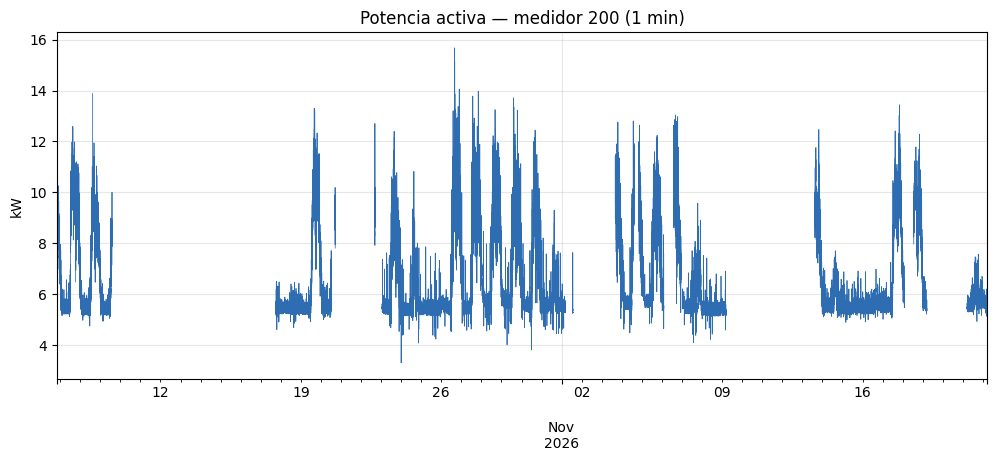

In [6]:
fig, ax = plt.subplots()
p1["P"].plot(ax=ax, lw=0.55, color="#2f6db3")
ax.set_title("Potencia activa — medidor 200 (1 min)")
ax.set_ylabel("kW"); ax.set_xlabel("")
fig.savefig(FIG / "01_serie_P.png", dpi=150, bbox_inches="tight")
plt.show()

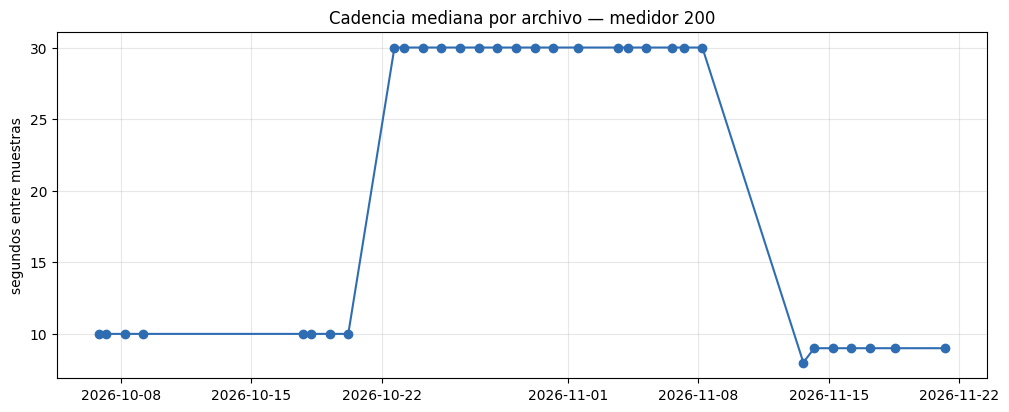

In [7]:
fig, ax = plt.subplots()
tmp = inv200.sort_values("inicio")
ax.plot(tmp["inicio"], tmp["dt_med_s"], "o-", color="#2f6db3")
ax.set_title("Cadencia mediana por archivo — medidor 200")
ax.set_ylabel("segundos entre muestras"); ax.set_xlabel("")
fig.savefig(FIG / "01_cadencia.png", dpi=150, bbox_inches="tight")
plt.show()

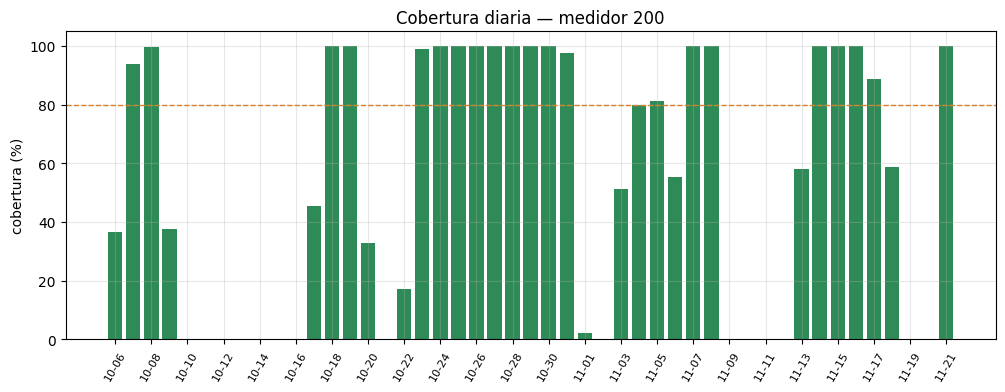

In [8]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(cov)), cov["cobertura_pct"], color="#2e8b57")
ax.set_xticks(range(0, len(cov), 2))
ax.set_xticklabels([str(d)[5:] for d in cov["dia"]][::2], rotation=60, fontsize=8)
ax.set_ylabel("cobertura (%)"); ax.set_title("Cobertura diaria — medidor 200")
ax.axhline(80, color="#d9822b", ls="--", lw=1)
fig.savefig(FIG / "01_cobertura.png", dpi=150, bbox_inches="tight")
plt.show()

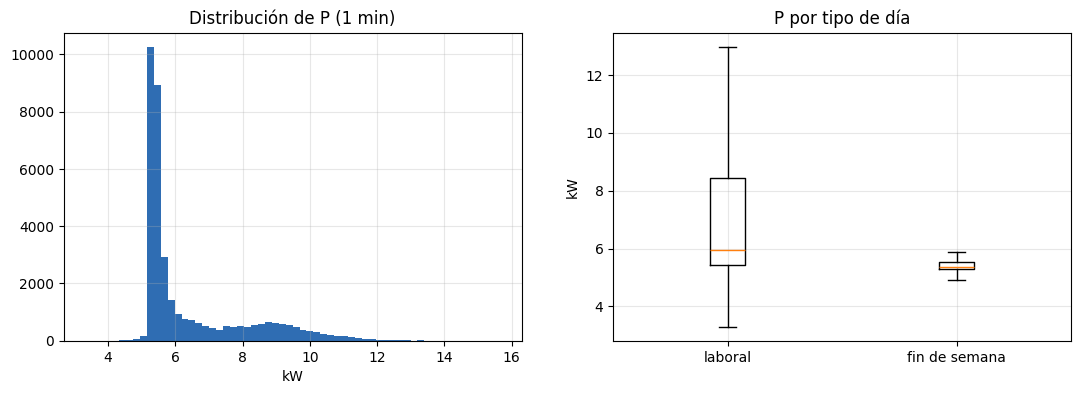

In [9]:
loc = p1.index.tz_convert("America/Bogota")
weekend = pd.Series(loc.dayofweek >= 5, index=p1.index)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(p1["P"].dropna(), bins=60, color="#2f6db3")
axes[0].set_title("Distribución de P (1 min)"); axes[0].set_xlabel("kW")
axes[1].boxplot([p1.loc[~weekend, "P"].dropna(), p1.loc[weekend, "P"].dropna()],
                tick_labels=["laboral", "fin de semana"], showfliers=False)
axes[1].set_title("P por tipo de día"); axes[1].set_ylabel("kW")
fig.savefig(FIG / "01_distribucion.png", dpi=150, bbox_inches="tight")
plt.show()

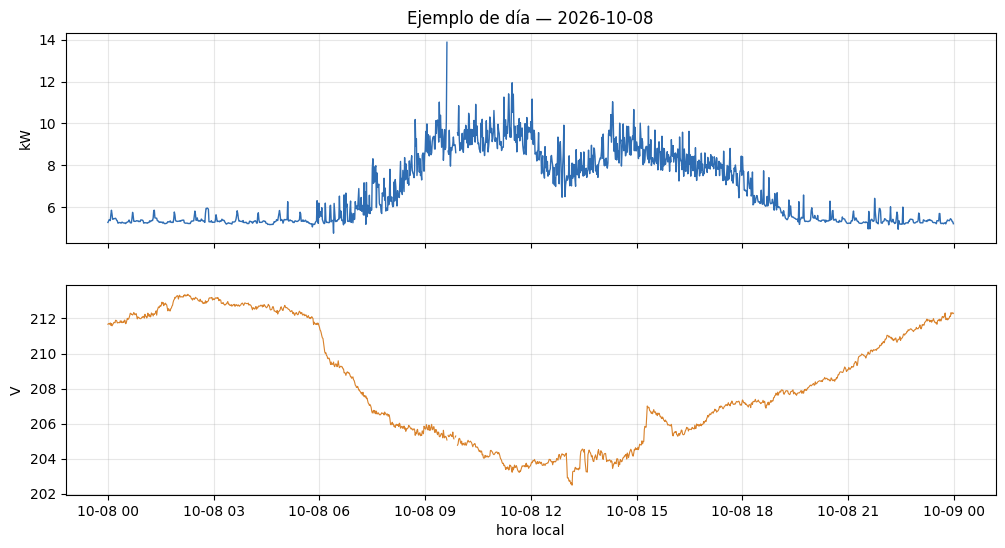

In [10]:
dia = pd.Timestamp("2026-10-08", tz="America/Bogota")
sel = p1.loc[dia:dia + pd.Timedelta(hours=23, minutes=59)]
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(sel.index.tz_convert("America/Bogota"), sel["P"], color="#2f6db3", lw=1)
axes[0].set_ylabel("kW"); axes[0].set_title("Ejemplo de día — 2026-10-08")
axes[1].plot(sel.index.tz_convert("America/Bogota"), sel["V"], color="#d9822b", lw=0.8)
axes[1].set_ylabel("V"); axes[1].set_xlabel("hora local")
fig.savefig(FIG / "01_dia_ejemplo.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Guardar resultados

La serie procesada es la base de `02_peak_model.ipynb`. Los días de 30 s tienen `n = 2`; los de 8–10 s, `n = 6–7`.

In [11]:
p1.to_csv(OUT / "medidor200_1min.csv")
inv200.to_csv(TAB / "01_inventario_200.csv", index=False)
cov.to_csv(TAB / "01_cobertura_200.csv", index=False)
gap_df.to_csv(TAB / "01_huecos_200.csv")
print("Guardado:", OUT / "medidor200_1min.csv")
print(p1["low_quality"].value_counts().to_string())

Guardado: C:\Users\Sebastian Tovar\Documents\Ing.Electronica\VIII\TAM\repo\Proyecto\data\processed\medidor200_1min.csv
low_quality
False    36101
True     30666
